# EAZY broadband photo-$z$
$$p(z \mid x) \propto \exp[-\chi^2(z)/2]p(z)$$
Fit EAZY templates to the same fixed CFHT u/HSC grizy photometry used by the
flow notebooks. Predict the full photometric test split, then evaluate its
spectroscopic subset. No redshift labels enter the fit.

Run from `nb/` with the project kernel. Restore the templates, filters, and EBV
extract described in [the data notes](../bin/data/README.md#optional-eazy-broadband-baseline).
Use the pinned eazy-photoz resources at commit `f651e94d91042a84906090a66d2a3fec75504e21`.

In [1]:
import os 
import numpy as np
from pathlib import Path
from astropy.table import Table

import eazy
from eazy.photoz import PhotoZ

from pzflow.utils import PDFSampler, coverage

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.5
mpl.rcParams['axes.xmargin'] = 1
mpl.rcParams['xtick.labelsize'] = 'x-large'
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.major.width'] = 1.5
mpl.rcParams['ytick.labelsize'] = 'x-large'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.major.width'] = 1.5
mpl.rcParams['legend.frameon'] = False

In [3]:
seed = 20261116
r_prior = True  # True enables the supplied approximate R-band magnitude prior.
stem = 'eazy_rprior' if r_prior else 'eazy'

## 2. Load the data and preserve the spatial split
Fluxes and errors are in microJy, ordered u, g, r, i, z, y, with shape (N, 6).
Use the fixed degraded photometry without adding noise. The spatial split is
0 = training, 1 = validation, 2 = test. EAZY uses fixed public templates.

In [4]:
keys = ['id', 'flux', 'fluxerr', 'zspec', 'has_specz', 'split', 'imag', 'cell']
with np.load('../data/parent.npz') as f:
    data = {key: f[key] for key in keys}

assert data['flux'].shape == data['fluxerr'].shape == (len(data['id']), 6)
assert np.isfinite(data['flux']).all()
assert np.isfinite(data['fluxerr']).all() and (data['fluxerr'] > 0).all()
assert len(np.unique(data['id'])) == len(data['id'])
for a, b in [(0, 1), (0, 2), (1, 2)]:
    assert not np.intersect1d(
        data['cell'][data['split'] == a], data['cell'][data['split'] == b]
    ).size
phot_test = np.flatnonzero(data['split'] == 2)
ids = data['id'][phot_test]
flux = data['flux'][phot_test].astype(float).copy()
err = data['fluxerr'][phot_test].astype(float).copy()
print(f'Fit {len(phot_test):,} photometric test galaxies')

Fit 26,635 photometric test galaxies


## 3. Correct the broadband photometry
Match Galactic extinction `ebv_mw` by ID and apply the released coefficients to
both flux and error, preserving signal-to-noise and negative measurements.
With `r_prior=True`, also apply `total_off2` to all bands for a total HSC r
magnitude. The supplied R prior is an approximate match to HSC r.

In [5]:
def match_rows(path, ids):
    # Auxiliary extracts can have a different selection and ordering from the parent.
    table = np.atleast_1d(np.genfromtxt(path, delimiter=',', names=True))
    table = table[np.argsort(table['id'])]
    j = np.searchsorted(table['id'], ids)
    if len(np.unique(table['id'])) != len(table) or np.any(j == len(table)):
        raise ValueError(f'Missing or duplicate IDs in {path}')
    if not np.array_equal(table['id'][j], ids):
        raise ValueError(f'Missing IDs in {path}')
    return table[j]


ebv = match_rows('../data/cosmos2020_specz/classic_i25_ebv.csv', ids)['ebv_mw']
assert np.isfinite(ebv).all()
coeff = np.array([4.807, 3.69, 2.715, 2.0, 1.515, 1.298])
correction = 10 ** (0.4 * ebv[:, None] * coeff[None, :])
flux *= correction
err *= correction
if r_prior:
    total_off = match_rows('../data/cosmos2020_specz/classic_magnitude_intervals.csv', ids)['total_off2']
    factor = 10 ** (-0.4 * total_off)
    assert np.isfinite(factor).all() and (factor > 0).all()
    flux *= factor[:, None]
    err *= factor[:, None]
assert np.isfinite(flux).all() and np.isfinite(err).all() and (err > 0).all()
np.testing.assert_allclose(
    flux / err, data['flux'][phot_test] / data['fluxerr'][phot_test], rtol=1e-6
)

## 4. Configure EAZY
Use native CFHT/HSC filters, 12 tweaked FSPS templates, template-error amplitude
0.20, and a 1% systematic-error floor. Keep the prior flat in redshift unless
`r_prior=True`. No zero-point fitting, template tuning, beta prior, or fixed spec-z.

In [6]:
filter_ids = [409, 314, 315, 316, 317, 318]  # CFHT cfh9302 u; HSC g/r/i/z/y.
catalog = Table({'id': ids})
for k, fid in enumerate(filter_ids):
    catalog[f'F{fid}'] = flux[:, k]
    catalog[f'E{fid}'] = err[:, k]
catalog.write('../data/eazy/_catalog.fits', overwrite=True)
translate = Path('../data/eazy/eazy.translate')
translate.write_text('')  # F409/E409-style names already identify the filters.

assets = Path(eazy.DATA_PATH)
params = dict(
    CATALOG_FILE='../data/eazy/_catalog.fits',
    CATALOG_FORMAT='fits',
    FILTERS_RES=str(assets / 'filters/FILTER.RES.latest'),
    TEMPLATES_FILE=str(assets / 'templates/fsps_full/tweak_fsps_QSF_12_v3.param'),
    TEMP_ERR_FILE=str(assets / 'templates/uvista_nmf/template_error_10.def'),
    WAVELENGTH_FILE=str(assets / 'templates/uvista_nmf/lambda.def'),
    PRIOR_FILE=str(assets / 'templates/prior_F160W_TAO.dat'),
    OUTPUT_DIRECTORY='../data/eazy/',
    MAIN_OUTPUT_FILE=stem,
    PRIOR_ABZP=23.9,
    APPLY_PRIOR='n',
    FIX_ZSPEC='n',
    Z_MIN=0.001,
    Z_MAX=10.0,
    Z_STEP=0.005,
    MW_EBV=0.0,
    CAT_HAS_EXTCORR='y',
    SYS_ERR=0.01,
    TEMP_ERR_A2=0.20,
    VERBOSITY=0,
    ADD_CGM='n',
    NOT_OBS_THRESHOLD=-1.0e10,
)
if r_prior:
    # EAZY-py needs a commented header for this original C-code prior file.
    prior_file = Path('../data/eazy/prior_R_zmax7_py.dat')
    prior_file.write_text('# ' + (Path(eazy.DATA_PATH) / 'templates/prior_R_zmax7.dat').read_text())
    params.update(PRIOR_FILE=str(prior_file), PRIOR_FILTER=315, APPLY_PRIOR='y')

## 5. Fit the photometric test split
Fit nonnegative template amplitudes at each redshift and apply the chosen prior.
The catalog contains only IDs, fluxes, and errors. Use one process (`n_proc=0`).

In [7]:
p = PhotoZ(
    params=params,
    translate_file=str(translate),
    load_prior=r_prior,
    n_proc=0,
    random_seed=seed,
)
assert p.NOBJ == len(ids) and p.NFILT == 6 and np.all(p.nusefilt == 6)
np.testing.assert_array_equal(np.asarray(p.cat['id']), ids)
p.fit_catalog(n_proc=0, get_best_fit=False, prior=r_prior, beta_prior=False)
p.compute_lnp(prior=r_prior, beta_prior=False, clip_wavelength=None)
p.evaluate_zml(prior=r_prior, beta_prior=False, clip_wavelength=None)
print(f'Fit {p.NOBJ:,} galaxies with {p.NTEMP} templates')

Read default param file: /opt/homebrew/Caskroom/miniconda/base/envs/pzflow/lib/python3.12/site-packages/eazy/data/zphot.param.default
Read CATALOG_FILE: ../data/eazy/_catalog.fits
   >>> NOBJ = 26635
F409 E409 (409): CFHT-megaprime-u9302-atmos+inst
F314 E314 (314): g_HSC.txt
F315 E315 (315): r_HSC.txt
F316 E316 (316): i_HSC.txt
F317 E317 (317): z_HSC.txt
F318 E318 (318): y_HSC.txt


Read PRIOR_FILE:  ../data/eazy/prior_R_zmax7_py.dat
Template grid: /opt/homebrew/Caskroom/miniconda/base/envs/pzflow/lib/python3.12/site-packages/eazy/data/eazy-photoz/templates/fsps_full/tweak_fsps_QSF_12_v3.param (this may take some time)


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:49<00:00,  4.10s/it]


Template   0: tweak_fsps_QSF_12_v3_001.dat (NZ=1).
Template   1: tweak_fsps_QSF_12_v3_002.dat (NZ=1).
Template   2: tweak_fsps_QSF_12_v3_003.dat (NZ=1).
Template   3: tweak_fsps_QSF_12_v3_004.dat (NZ=1).
Template   4: tweak_fsps_QSF_12_v3_005.dat (NZ=1).
Template   5: tweak_fsps_QSF_12_v3_006.dat (NZ=1).
Template   6: tweak_fsps_QSF_12_v3_007.dat (NZ=1).
Template   7: tweak_fsps_QSF_12_v3_008.dat (NZ=1).
Template   8: tweak_fsps_QSF_12_v3_009.dat (NZ=1).
Template   9: tweak_fsps_QSF_12_v3_010.dat (NZ=1).
Template  10: tweak_fsps_QSF_12_v3_011.dat (NZ=1).
Template  11: tweak_fsps_QSF_12_v3_012.dat (NZ=1).
Process templates: 49.462 s


480it [00:00, 587.24it/s]
480it [08:32,  1.07s/it]


Fit 512.6 s (n_proc=1, NOBJ=26635)
Fit 26,635 galaxies with 12 templates


## 6. Predict redshift quantiles
Normalize the piecewise-linear redshift PDFs and invert their integrated density.
Quantiles are 2.5%, 16%, 50%, 84%, and 97.5%, as in the flow notebooks.
Use the posterior median for comparisons; EAZY's `zml` is a separate estimate.

In [8]:
def pdf_quantiles(sampler, probs=(0.025, 0.16, 0.5, 0.84, 0.975)):
    rows = np.arange(len(sampler.p))
    quantiles = []
    for prob in probs:
        j = np.clip((sampler.c <= prob).sum(axis=1) - 1, 0, len(sampler.grid) - 2)
        width = np.diff(sampler.grid)[j]
        a = sampler.p[rows, j]
        slope = (sampler.p[rows, j + 1] - a) / width
        mass = np.maximum(prob - sampler.c[rows, j], 0)
        den = a + np.sqrt(np.maximum(a * a + 2 * slope * mass, 0))
        step = np.divide(2 * mass, den, out=np.zeros_like(mass), where=den > 0)
        quantiles.append(sampler.grid[j] + np.clip(step, 0, width))
    return np.column_stack(quantiles)


grid = np.asarray(p.zgrid)
pdf = np.exp(p.lnp - p.lnp.max(axis=1)[:, None])
assert np.isfinite(pdf).all() and (pdf >= 0).all()
norm = np.trapezoid(pdf, grid, axis=1)
assert (norm > 0).all()
pdf /= norm[:, None]
np.testing.assert_allclose(np.trapezoid(pdf, grid, axis=1), 1, atol=1e-6)
sampler = PDFSampler(grid, pdf)
q_all = pdf_quantiles(sampler)
assert q_all.shape == (len(phot_test), 5)
assert np.isfinite(q_all).all() and (np.diff(q_all, axis=1) >= 0).all()
print(f'Predicted {len(q_all):,} test galaxies without redshift labels')

Predicted 26,635 test galaxies without redshift labels


## 7. Evaluate against held-out spectroscopy
Use the same `has_specz` test subset as the flow notebooks. Report accuracy and
coverage for this selected spectroscopic sample; these diagnostics do not tune the fit.

In [9]:
scored = data['has_specz'][phot_test]
test = phot_test[scored]
ztest = data['zspec'][test]
q = q_all[scored]
assert np.isfinite(ztest).all() and (ztest > 0).all()
pit = sampler.pit(ztest, indices=np.flatnonzero(scored))

# Evaluate the same piecewise-linear PDF for NLL; floor only the log at float tiny.
rows = np.flatnonzero(scored)
j = np.clip(np.searchsorted(grid, ztest, side='right') - 1, 0, len(grid) - 2)
w = (ztest - grid[j]) / np.diff(grid)[j]
density = sampler.p[rows, j] * (1 - w) + sampler.p[rows, j + 1] * w
density[(ztest < grid[0]) | (ztest > grid[-1])] = 0
nll = -np.log(np.maximum(density, np.finfo(float).tiny))
residual = (q[:, 2] - ztest) / (1 + ztest)
c68, c95 = coverage(pit)
metrics = {
    'n': len(test),
    'bias': float(np.median(residual)),
    'nmad': float(1.4826 * np.median(np.abs(residual - np.median(residual)))),
    'outlier_fraction': float(np.mean(np.abs(residual) > 0.15)),
    'coverage68': float(c68),
    'coverage95': float(c95),
    'median_width68': float(np.median(q[:, 3] - q[:, 1])),
}
#print(json.dumps(metrics, indent=2))

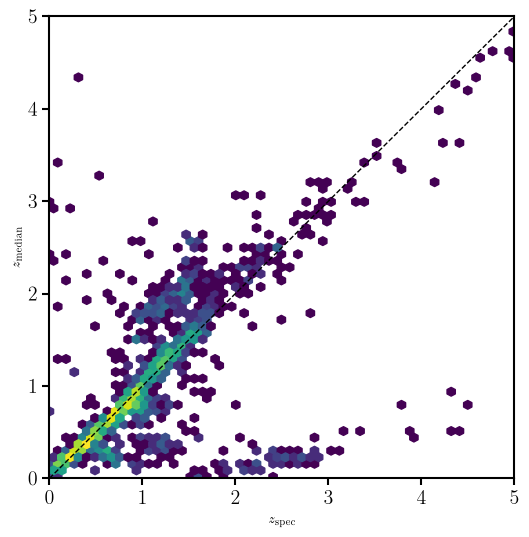

In [10]:
fig = plt.figure(figsize=(6, 6))
sub = fig.add_subplot(111)
sub.hexbin(ztest, q[:, 2], gridsize=60, bins='log', mincnt=1, cmap='viridis')
sub.plot([0, 5], [0, 5], 'k--', lw=1)
sub.set(xlim=(0, 5), ylim=(0, 5), xlabel=r'$z_{\mathrm{spec}}$', ylabel=r'$z_{\mathrm{median}}$')
plt.show()

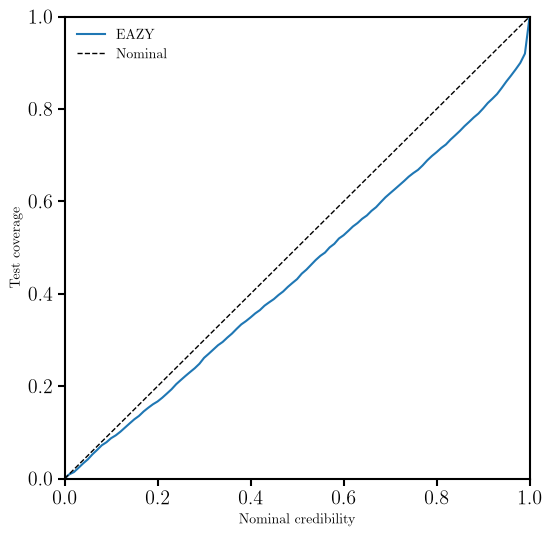

In [11]:
credibility = np.linspace(0, 1, 101)
rank = np.abs(2 * pit - 1)
curve = np.array([(rank <= level).mean() for level in credibility])
fig = plt.figure(figsize=(6, 6))
sub = fig.add_subplot(111)
sub.plot(credibility, curve, label='EAZY')
sub.plot([0, 1], [0, 1], 'k--', lw=1, label='Nominal')
sub.set(xlim=(0, 1), ylim=(0, 1), xlabel='Nominal credibility', ylabel='Test coverage')
sub.legend()
plt.show()

Example PDFs span the same test sample's native i-band magnitudes.
Dashed lines show held-out spectroscopy for evaluation only.

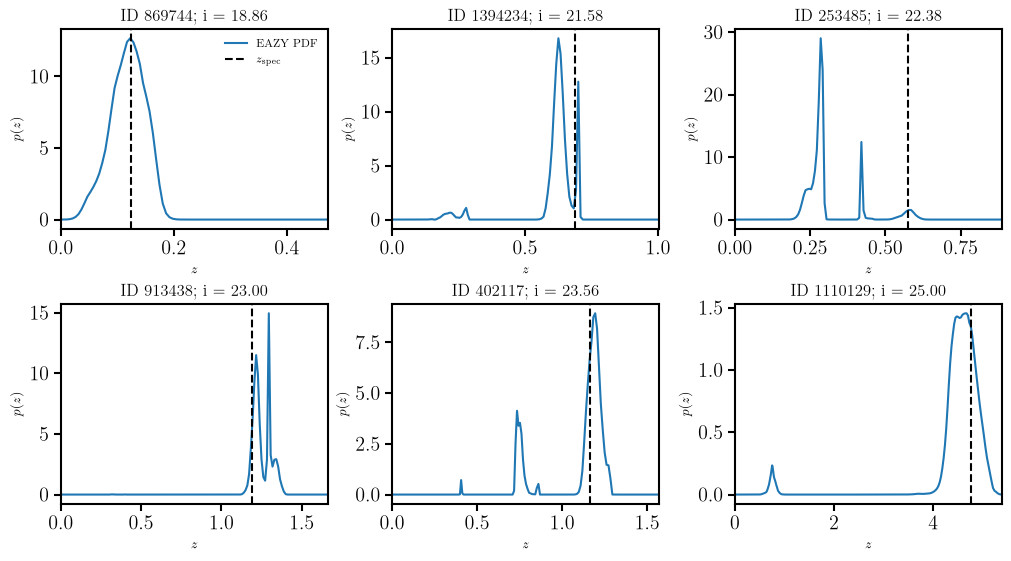

In [12]:
order = np.argsort(data['imag'][test])
examples = order[np.linspace(0, len(order) - 1, 6, dtype=int)]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, j in zip(axes.flat, examples):
    row = rows[j]
    ax.plot(grid, pdf[row], label='EAZY PDF')
    ax.axvline(ztest[j], color='k', ls='--', label=r'$z_{\mathrm{spec}}$')
    ax.set(xlim=(0, min(10, max(q[j, 4], ztest[j]) + 0.3)), xlabel=r'$z$', ylabel=r'$p(z)$')
    ax.set_title(f'ID {data["id"][test[j]]}; i = {data["imag"][test[j]]:.2f}')
axes.flat[0].legend(fontsize=8)
plt.show()

## 8. Save PDFs and predictions
Save the shared `id`, `zspec`, `imag`, `flux`, `fluxerr`, `quantiles`, `pit`, and
`nll` fields to `data/eazy_test_predictions.npz`. Also retain full photometric
test predictions, PDFs, and fitting settings. The optional R-prior run uses the
`eazy_rprior` prefix. Fluxes in prediction files remain the original parent values.

In [13]:
prediction = {key: data[key][test] for key in ['id', 'zspec', 'imag', 'flux', 'fluxerr']}
prediction.update(quantiles=q, pit=pit, nll=nll)
np.savez_compressed(f'../data/{stem}_test_predictions.npz', **prediction)
np.savez_compressed(
    f'../data/{stem}_photometric_test_predictions.npz',
    id=ids,
    flux=data['flux'][phot_test],
    fluxerr=data['fluxerr'][phot_test],
    quantiles=q_all,
)
np.savez_compressed(
    f'../data/{stem}_posteriors.npz',
    id=ids,
    grid=grid,
    pdf=pdf,
    zml=p.zml,
    flux=data['flux'][phot_test],
    fluxerr=data['fluxerr'][phot_test],
    eazy_flux=flux,
    eazy_fluxerr=err,
)

# settings = {
#     'seed': seed,
#     'r_prior': r_prior,
#     'params': params,
#     'extinction_coefficients': coeff.tolist(),
#     'eazy_version': eazy.__version__,
#     'n_photometric_test': len(phot_test),
#     'n_spec_test': len(test),
#     'metrics': metrics,
# }
# with open(f'../data/{stem}_run.json', 'w') as f:
#     json.dump(settings, f, indent=2, allow_nan=False)
#     f.write('\n')
# print(f'Saved {stem} predictions and PDFs')